In [1]:
!pip install -q pandas matplotlib numpy scikit-learn

In [4]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_excel(
    "merged_fb_tiktok.xlsx", sheet_name="MERGED_DATA"
)

print("Kích thước:", df.shape)
df.head(5)

Saving merged_fb_tiktok.xlsx to merged_fb_tiktok (2).xlsx
Kích thước: (3314, 8)


,Comment ID,Source,Original ID,RAW Text,Clean Text,Text_PhoBERT,Text_TFIDF,Final Label
0,1,Facebook,2,Anh già r mà anh vẫn đỉnh voãi\n🤣,anh già rồi anh vẫn đỉnh rất,NaN,NaN,Positive
1,2,Facebook,3,Nhữ Thị Thảo anh zai đóng phản diện là chuẩn c...,anh_trai đóng phản_diện chuẩn luôn_luôn,NaN,NaN,Positive
2,3,Facebook,4,Nhữ Thị Thảo 1 mình a 3 em trong phim mà lại 🤣🤣,mình anh_em trong phim mà_lại,NaN,NaN,Neutral
3,4,Facebook,9,Nhữ Thị Thảo anh Ngoan ở bên Thiên đường máu l...,anh ngoan bên thiên đường_máu làm trùm rồi qua...,NaN,NaN,Neutral
4,5,Facebook,10,Cậu Cả chén bà bầu + 1 bà bếp ngồi ôm gối thôi mà,chén bà bầu bà bếp ngồi ôm gối thôi,NaN,NaN,Neutral


In [5]:
data = df[["Clean Text", "Final Label"]].copy()

data = data.rename(columns={
    "Clean Text": "text",
    "Final Label": "label"
})

print("Kích thước dữ liệu:", data.shape)
display(data.head())

Kích thước dữ liệu: (3314, 2)


,text,label
0,anh già rồi anh vẫn đỉnh rất,Positive
1,anh_trai đóng phản_diện chuẩn luôn_luôn,Positive
2,mình anh_em trong phim mà_lại,Neutral
3,anh ngoan bên thiên đường_máu làm trùm rồi qua...,Neutral
4,chén bà bầu bà bếp ngồi ôm gối thôi,Neutral


In [7]:

label_counts = data["label"].value_counts()

label_precent = data["label"].value_counts(normalize=True)* 100

label_stats = pd.DataFrame({
    "Số lượng": label_counts,
    "Tỉ lệ": label_precent.round(2)
})

display(label_stats)


,Số lượng,Tỉ lệ
label,,
Positive,2062,62.22
Neutral,692,20.88
Negative,560,16.90


In [8]:
#Chia dữ liệu
from sklearn.model_selection import  train_test_split

X= data["text"]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=18,
    stratify=y
)

print("Số mẫu Train:", len(X_train))
print("Số mẫu Test:", len(X_test))

print("\nPhân bố nhãn Train:")
print(y_train.value_counts())

print("\nPhân bố nhãn Test:")
print(y_test.value_counts())

Số mẫu Train: 2651
Số mẫu Test: 663

Phân bố nhãn Train:
label
Positive    1649
Neutral      554
Negative     448
Name: count, dtype: int64

Phân bố nhãn Test:
label
Positive    413
Neutral     138
Negative    112
Name: count, dtype: int64


In [11]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=18
)



In [12]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

bow_ovr = Pipeline([
    ("bow", CountVectorizer(ngram_range=(1,2))),
    ("svm", LinearSVC(
        C=1.0,
        random_state=18
    ))
])


scores_bow_ovr = cross_val_score(
    bow_ovr,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Macro F1 từng fold:", scores_bow_ovr.round(4))
print("Macro F1 trung bình:", scores_bow_ovr.mean().round(4))

Macro F1 từng fold: [0.6206 0.6011 0.5668 0.6044 0.5671]
Macro F1 trung bình: 0.592


In [15]:
#Thử với OvO
from sklearn.multiclass import OneVsOneClassifier
bow_ovo = Pipeline([
    ("bow", CountVectorizer(ngram_range=(1,2))),
    ("svm", OneVsOneClassifier(
        LinearSVC(
            C=1.0,
            random_state=18
        )
    ))
])

scores_bow_ovo = cross_val_score(
    bow_ovo, X_train, y_train,
    cv=cv, scoring="f1_macro"
)

print("Macro F1 từng fold:", scores_bow_ovo.round(4))
print("Macro F1 trung bình:", scores_bow_ovo.mean().round(4))

Macro F1 từng fold: [0.6072 0.5995 0.5477 0.5963 0.5706]
Macro F1 trung bình: 0.5843


In [17]:
#tối ưu cho Bow _ OvR
from sklearn.model_selection import GridSearchCV

param_grid_ovr = {
    "svm__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    "svm__class_weight": [None, "balanced"],
    "svm__loss": ["hinge", "squared_hinge"],
    "svm__dual": [True]
}


grid_ovr = GridSearchCV(
    estimator=bow_ovr,
    param_grid=param_grid_ovr,
    scoring="f1_macro",
    cv=cv,
    refit=True,
    n_jobs=2
)

grid_ovr.fit(X_train, y_train)

print("Tham số tốt nhất:")
print(grid_ovr.best_params_)

print("\nMacro F1 CV tốt nhất:")
print(round(grid_ovr.best_score_, 4))

# 5. Hiển thị 5 cấu hình tốt nhất
results_ovr = pd.DataFrame(grid_ovr.cv_results_)

top5_ovr = results_ovr.sort_values(
    "rank_test_score"
).head(5)

display(top5_ovr[[
    "param_svm__C",
    "param_svm__class_weight",
    "param_svm__loss",
    "mean_test_score",
    "std_test_score"
]])

Tham số tốt nhất:
{'svm__C': 0.1, 'svm__class_weight': 'balanced', 'svm__dual': True, 'svm__loss': 'hinge'}

Macro F1 CV tốt nhất:
0.6122


,param_svm__C,param_svm__class_weight,param_svm__loss,mean_test_score,std_test_score
10,0.10,balanced,hinge,0.612196,0.029733
11,0.10,balanced,squared_hinge,0.609993,0.031487
7,0.03,balanced,squared_hinge,0.606222,0.034693
6,0.03,balanced,hinge,0.604958,0.024913
15,0.30,balanced,squared_hinge,0.603038,0.025427


In [19]:

param_grid_bow_ovr = {
    "bow__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "bow__min_df": [1, 2, 3, 5],
    "bow__binary": [False, True]
}

grid_bow_ovr = GridSearchCV(
    estimator=grid_ovr.best_estimator_,
    param_grid=param_grid_bow_ovr,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_bow_ovr.fit(X_train, y_train)

print("Tham số BoW tốt nhất (OvR):")
print(grid_bow_ovr.best_params_)

print("\nMacro F1 CV tốt nhất (OvR):")
print(round(grid_bow_ovr.best_score_, 4))

results_bow_ovr = pd.DataFrame(grid_bow_ovr.cv_results_)

top5_bow_ovr = results_bow_ovr.sort_values(
    "rank_test_score"
).head(5)

display(top5_bow_ovr[[
    "param_bow__ngram_range",
    "param_bow__min_df",
    "param_bow__binary",
    "mean_test_score",
    "std_test_score"
]])


Tham số BoW tốt nhất (OvR):
{'bow__binary': False, 'bow__min_df': 1, 'bow__ngram_range': (1, 2)}

Macro F1 CV tốt nhất (OvR):
0.6122


,param_bow__ngram_range,param_bow__min_df,param_bow__binary,mean_test_score,std_test_score
1,"(1, 2)",1,False,0.612196,0.029733
4,"(1, 2)",2,False,0.612084,0.020073
0,"(1, 1)",1,False,0.611712,0.026399
16,"(1, 2)",2,True,0.610335,0.022642
22,"(1, 2)",5,True,0.609477,0.022760


**Tối ưu cho BoW - OvO**

In [18]:
#Tối ưu cho Bow _ OvO

param_grid_ovo = {
    "svm__estimator__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    "svm__estimator__class_weight": [None, "balanced"],
    "svm__estimator__loss": ["hinge", "squared_hinge"],
    "svm__estimator__dual": [True]
}

grid_ovo = GridSearchCV(
    estimator=bow_ovo,
    param_grid=param_grid_ovo,
    scoring="f1_macro",
    cv=cv,
    n_jobs=2,
    refit=True
)

grid_ovo.fit(X_train, y_train)

print("Tham số tốt nhất:")
print(grid_ovo.best_params_)

print("\nMacro F1 CV tốt nhất:")
print(round(grid_ovo.best_score_, 4))

results_ovo = pd.DataFrame(grid_ovo.cv_results_)

top5_ovo = results_ovo.sort_values(
    "rank_test_score"
).head(5)

display(top5_ovo[[
    "param_svm__estimator__C",
    "param_svm__estimator__class_weight",
    "param_svm__estimator__loss",
    "mean_test_score",
    "std_test_score"
]])

Tham số tốt nhất:
{'svm__estimator__C': 0.1, 'svm__estimator__class_weight': 'balanced', 'svm__estimator__dual': True, 'svm__estimator__loss': 'squared_hinge'}

Macro F1 CV tốt nhất:
0.6088


,param_svm__estimator__C,param_svm__estimator__class_weight,param_svm__estimator__loss,mean_test_score,std_test_score
11,0.10,balanced,squared_hinge,0.608757,0.021775
7,0.03,balanced,squared_hinge,0.605873,0.013023
10,0.10,balanced,hinge,0.605465,0.021419
15,0.30,balanced,squared_hinge,0.601780,0.022757
14,0.30,balanced,hinge,0.598841,0.030201


In [21]:
param_grid_bow_ovo = {
    "bow__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "bow__min_df": [1, 2, 3, 5],
    "bow__binary": [False, True]
}

grid_bow_ovo = GridSearchCV(
    estimator=grid_ovo.best_estimator_,
    param_grid=param_grid_bow_ovo,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_bow_ovo.fit(X_train, y_train)

print("Tham số BoW tốt nhất (OvO):")
print(grid_bow_ovo.best_params_)

print("\nMacro F1 CV tốt nhất (OvO):")
print(round(grid_bow_ovo.best_score_, 4))

results_bow_ovo = pd.DataFrame(grid_bow_ovo.cv_results_)

top5_bow_ovo = results_bow_ovo.sort_values(
    "rank_test_score"
).head(5)

display(top5_bow_ovo[[
    "param_bow__ngram_range",
    "param_bow__min_df",
    "param_bow__binary",
    "mean_test_score",
    "std_test_score"
]])


Tham số BoW tốt nhất (OvO):
{'bow__binary': False, 'bow__min_df': 3, 'bow__ngram_range': (1, 3)}

Macro F1 CV tốt nhất (OvO):
0.6117


,param_bow__ngram_range,param_bow__min_df,param_bow__binary,mean_test_score,std_test_score
8,"(1, 3)",3,False,0.611698,0.013962
7,"(1, 2)",3,False,0.609513,0.014965
2,"(1, 3)",1,False,0.609413,0.028395
1,"(1, 2)",1,False,0.608757,0.021775
4,"(1, 2)",2,False,0.607071,0.016868


### **Khả năng phân loại nhãn**

In [22]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, f1_score

y_pred_ovr_oof = cross_val_predict(
    grid_bow_ovr.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

y_pred_ovo_oof = cross_val_predict(
    grid_bow_ovo.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)


print("===== BoW + SVM (OvR) =====")
print(classification_report(
    y_train,
    y_pred_ovr_oof,
    digits=4,
    zero_division=0
))

# 4. Classification Report của OvO
print("\n===== BoW + SVM (OvO) =====")
print(classification_report(
    y_train,
    y_pred_ovo_oof,
    digits=4,
    zero_division=0
))


===== BoW + SVM (OvR) =====
              precision    recall  f1-score   support

    Negative     0.5443    0.3973    0.4594       448
     Neutral     0.5478    0.5686    0.5580       554
    Positive     0.7970    0.8454    0.8205      1649

    accuracy                         0.7118      2651
   macro avg     0.6297    0.6038    0.6126      2651
weighted avg     0.7022    0.7118    0.7046      2651


===== BoW + SVM (OvO) =====
              precision    recall  f1-score   support

    Negative     0.4811    0.4821    0.4816       448
     Neutral     0.5075    0.6137    0.5556       554
    Positive     0.8290    0.7702    0.7985      1649

    accuracy                         0.6888      2651
   macro avg     0.6058    0.6220    0.6119      2651
weighted avg     0.7030    0.6888    0.6942      2651



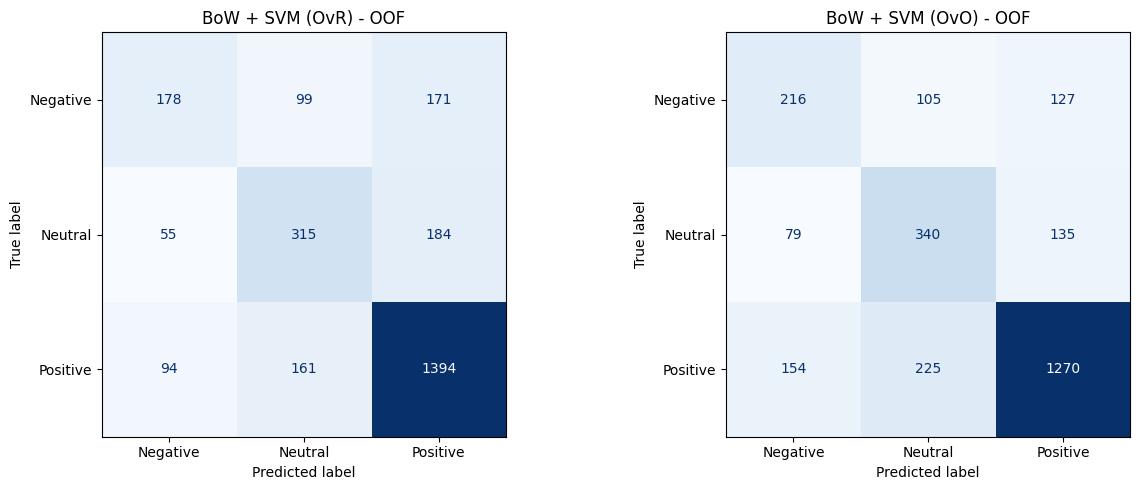

In [23]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["Negative", "Neutral", "Positive"]

cm_ovr = confusion_matrix(
    y_train, y_pred_ovr_oof, labels=labels
)

cm_ovo = confusion_matrix(
    y_train, y_pred_ovo_oof, labels=labels
)

# Vẽ hai ma trận cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_ovr,
    display_labels=labels
).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)

axes[0].set_title("BoW + SVM (OvR) - OOF")

ConfusionMatrixDisplay(
    confusion_matrix=cm_ovo,
    display_labels=labels
).plot(ax=axes[1], cmap="Blues", values_format="d", colorbar=False)

axes[1].set_title("BoW + SVM (OvO) - OOF")

plt.tight_layout()
plt.show()



###  Lựa chọn mô hình BoW + SVM tốt nhất

Sau tối ưu, OvR đạt Macro F1 CV = **0.6122**, cao hơn OvO = **0.6117**.
Vì vậy, nhóm chọn **BoW + Linear SVM (OvR)** làm mô hình tốt nhất.
Cấu hình: `C=0.1`, `class_weight='balanced'`, `loss='hinge'`, `ngram_range=(1,2)`, `min_df=1`, `binary=False`.

In [27]:

best_bow_svm = grid_bow_ovr.best_estimator_

bow = best_bow_svm.named_steps["bow"]
svm = best_bow_svm.named_steps["svm"]

features = bow.get_feature_names_out()

for i in range(3):
    weights = pd.Series(svm.coef_[i], index=features)

    print("\nNhãn:", svm.classes_[i])
    print(weights.nlargest(10).round(4))



Nhãn: Negative
xàm             0.8415
dở              0.7012
không hay       0.6896
bình_thường     0.6617
thua            0.5834
rác             0.5660
seeding         0.5632
nhạt            0.5615
không_hay       0.5533
tuyên_truyền    0.4775
dtype: float64

Nhãn: Neutral
hay không     0.6878
để đi         0.6363
giá           0.5429
chiếu         0.5188
tuổi          0.5010
xem được      0.4922
18            0.4721
mã            0.4636
beta          0.4439
phải không    0.4210
dtype: float64

Nhãn: Positive
hay        0.9146
đỉnh       0.6582
cuốn       0.5595
mê         0.4745
đã         0.4084
liền       0.4038
phải đi    0.3756
ngầu       0.3593
khóc       0.3478
đáng       0.3308
dtype: float64


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

best_bow_svm = grid_bow_ovr.best_estimator_

y_pred_bow = best_bow_svm.predict(X_test)

accuracy_bow = accuracy_score(y_test, y_pred_bow)
precision_bow = precision_score(y_test, y_pred_bow, average="macro")
recall_bow = recall_score(y_test, y_pred_bow, average="macro")
macro_f1_bow = f1_score(y_test, y_pred_bow, average="macro")

print("===== BoW + SVM (OvR) - TEST =====")
print("Accuracy:", round(accuracy_bow, 4))
print("Macro Precision:", round(precision_bow, 4))
print("Macro Recall:", round(recall_bow, 4))
print("Macro F1:", round(macro_f1_bow, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_bow, digits=4))

===== BoW + SVM (OvR) - TEST =====
Accuracy: 0.7421
Macro Precision: 0.6683
Macro Recall: 0.6532
Macro F1: 0.66

Classification Report:
              precision    recall  f1-score   support

    Negative     0.5800    0.5179    0.5472       112
     Neutral     0.6000    0.5870    0.5934       138
    Positive     0.8248    0.8547    0.8395       413

    accuracy                         0.7421       663
   macro avg     0.6683    0.6532    0.6600       663
weighted avg     0.7366    0.7421    0.7389       663



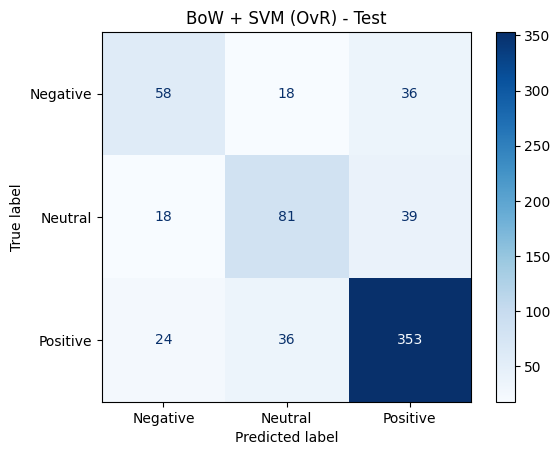

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["Negative", "Neutral", "Positive"]

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bow,
    labels=labels,
    cmap="Blues",
    values_format="d"
)
plt.title("BoW + SVM (OvR) - Test")
plt.show()

In [31]:
import joblib
from google.colab import files

joblib.dump(best_bow_svm, "best_bow_svm_v2.joblib")
files.download("best_bow_svm_v2.joblib")

print("Đã lưu")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Đã lưu
